<a href="https://colab.research.google.com/github/shivangitarawat/Assignment_Portalwiz/blob/main/Assignment_Portalwiz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Importing the Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [ ]:
os.makedirs("exports", exist_ok=True)

In [ ]:
SUBS_PATH = "raw_user_subscriptions.csv"
ACT_PATH = "raw_user_activity.csv"

In [ ]:
if os.path.exists(SUBS_PATH) and os.path.exists(ACT_PATH):
    print("Loading uploaded CSV files...")
    df_subs_raw = pd.read_csv(SUBS_PATH)
    df_act_raw = pd.read_csv(ACT_PATH)
else:
    print("Files not found in root. Generating mock datasets matching the assignment schema...")
    np.random.seed(42)
    n_users = 1000

    # Generate user IDs
    user_ids = [f"U_{i:04d}" for i in range(1, n_users + 1)]

    # Generate subscription data
    signup_dates = pd.date_range(end="2026-09-30", periods=365)
    plans = ["Basic", "Pro", "Enterprise", None]
    plan_weights = [0.55, 0.30, 0.12, 0.03]
    fees = {"Basic": 9.99, "Pro": 24.99, "Enterprise": 79.99}

    sub_data = []
    for uid in user_ids:
        s_date = np.random.choice(signup_dates)
        plan = np.random.choice(plans, p=plan_weights)
        fee = fees.get(plan, np.nan)
        churn_rnd = np.random.rand()

        if churn_rnd < 0.25:
            churn_status = "Cancelled"
            cancellation_date = s_date + pd.Timedelta(days=int(np.random.randint(10, 180)))
        elif churn_rnd < 0.90:
            churn_status = "Active"
            cancellation_date = pd.NaT
        else:
            churn_status = None
            cancellation_date = pd.NaT

        sub_data.append([uid, s_date, plan, fee, churn_status, cancellation_date])

    df_subs_raw = pd.DataFrame(
        sub_data,
        columns=["user_id", "signup_date", "plan_type", "monthly_fee", "churn_status", "cancellation_date"]
    )

    # Generate activity logs (past 90 days)
    activity_dates = pd.date_range(start="2026-07-01", end="2026-09-30")
    act_data = []
    for _ in range(15000):
        uid = np.random.choice(user_ids)
        s_date = np.random.choice(activity_dates)
        dur = np.random.exponential(scale=25)

        # Inject anomalies
        if np.random.rand() < 0.02:
            dur = -5.0
        if np.random.rand() < 0.01:
            dur = 1440.0
        if np.random.rand() < 0.03:
            dur = np.nan

        feats = np.random.poisson(lam=4)
        tickets = np.random.choice([0, 1, 2, 3, 20], p=[0.85, 0.10, 0.03, 0.015, 0.005])
        act_data.append([uid, s_date, feats, tickets, dur])

    df_act_raw = pd.DataFrame(
        act_data,
        columns=["user_id", "session_date", "feature_usage_count", "support_tickets", "session_duration_mins"]
    )

    # Inject duplicate records
    df_act_raw = pd.concat([df_act_raw, df_act_raw.sample(300, random_state=42)], ignore_index=True)
    print("Mock data generated successfully.")

Files not found in root. Generating mock datasets matching the assignment schema...
Mock data generated successfully.


In [ ]:
# Create working copies
df_subs = df_subs_raw.copy()
df_act = df_act_raw.copy()

In [ ]:
# Deduplication
initial_act_count = len(df_act)
df_act = df_act.drop_duplicates(subset=['user_id', 'session_date', 'feature_usage_count', 'session_duration_mins'])
print(f"Deduplication: Removed {initial_act_count - len(df_act)} duplicate records.")

Deduplication: Removed 300 duplicate records.


In [ ]:
# Date Parsing
df_subs['signup_date'] = pd.to_datetime(df_subs['signup_date'])
df_subs['cancellation_date'] = pd.to_datetime(df_subs['cancellation_date'])
df_act['session_date'] = pd.to_datetime(df_act['session_date'])

In [ ]:
# Missing Value Handling: churn_status
df_subs.loc[df_subs['cancellation_date'].notna(), 'churn_status'] = 'Cancelled'
df_subs['churn_status'] = df_subs['churn_status'].fillna('Active')

In [ ]:
# Outlier & Anomaly Handling: session_duration_mins
df_act.loc[df_act['session_duration_mins'] < 0, 'session_duration_mins'] = np.nan
df_act.loc[df_act['session_duration_mins'] > 300, 'session_duration_mins'] = 300.0

med_duration = df_act['session_duration_mins'].median()
df_act['session_duration_mins'] = df_act['session_duration_mins'].fillna(med_duration)

In [ ]:
# Bounding support tickets and feature usage
df_act['support_tickets'] = df_act['support_tickets'].clip(lower=0, upper=5)
df_act['feature_usage_count'] = df_act['feature_usage_count'].clip(lower=0)

In [ ]:
# Save cleaned datasets to exports folder
df_subs.to_csv("exports/cleaned_user_subscriptions.csv", index=False)
df_act.to_csv("exports/cleaned_user_activity.csv", index=False)
print("Task 1 complete: Cleaned CSV files saved to exports/ folder.")

Task 1 complete: Cleaned CSV files saved to exports/ folder.


In [ ]:
# Calculate MAU, DAU, and Stickiness Ratio
max_date = df_act['session_date'].max()
window_30d = max_date - pd.Timedelta(days=29)

df_last_30d = df_act[df_act['session_date'] >= window_30d]
mau = df_last_30d['user_id'].nunique()
dau = df_last_30d.groupby('session_date')['user_id'].nunique().mean()
stickiness = (dau / mau) * 100 if mau > 0 else 0

In [ ]:
# Calculate Churn Rate, ARPU, and LTV Proxy
total_users = len(df_subs)
churn_count = (df_subs['churn_status'] == 'Cancelled').sum()
churn_rate = (churn_count / total_users) * 100
arpu = df_subs['monthly_fee'].mean()
monthly_churn_dec = max(churn_rate / 100 / 12, 0.01)
ltv = arpu / monthly_churn_dec

In [ ]:
# Calculate Customer Health Index Score (0 - 100 scale)
user_agg = df_act.groupby('user_id').agg(
    total_sessions=('session_date', 'count'),
    total_features=('feature_usage_count', 'sum'),
    total_tickets=('support_tickets', 'sum')
).reset_index()

def min_max(s):
    denom = s.max() - s.min()
    return (s - s.min()) / denom if denom > 0 else 0.5

user_agg['freq_norm'] = min_max(user_agg['total_sessions'])
user_agg['feat_norm'] = min_max(user_agg['total_features'])
user_agg['ticket_penalty'] = min_max(user_agg['total_tickets'])

user_agg['health_score'] = (
    (0.40 * user_agg['freq_norm'] +
     0.45 * user_agg['feat_norm'] +
     0.15 * (1 - user_agg['ticket_penalty'])) * 100
).round(2)

user_agg.to_csv("exports/user_health_scores.csv", index=False)

In [ ]:
# Display summary table of all calculated KPIs
kpis_df = pd.DataFrame({
    "Metric": [
        "Monthly Active Users (MAU)",
        "Daily Active Users (DAU - Avg)",
        "DAU/MAU Stickiness Ratio",
        "Overall Churn Rate",
        "Average Revenue Per User (ARPU)",
        "Customer Lifetime Value (LTV Proxy)",
        "Mean Customer Health Score"
    ],
    "Value": [
        f"{mau:,}",
        f"{dau:.2f}",
        f"{stickiness:.2f}%",
        f"{churn_rate:.2f}%",
        f"${arpu:.2f}",
        f"${ltv:.2f}",
        f"{user_agg['health_score'].mean():.2f} / 100"
    ]
})

kpis_df

,Metric,Value
0,Monthly Active Users (MAU),991
1,Daily Active Users (DAU - Avg),150.83
2,DAU/MAU Stickiness Ratio,15.22%
3,Overall Churn Rate,26.20%
4,Average Revenue Per User (ARPU),$24.59
5,Customer Lifetime Value (LTV Proxy),$1126.04
6,Mean Customer Health Score,47.97 / 100


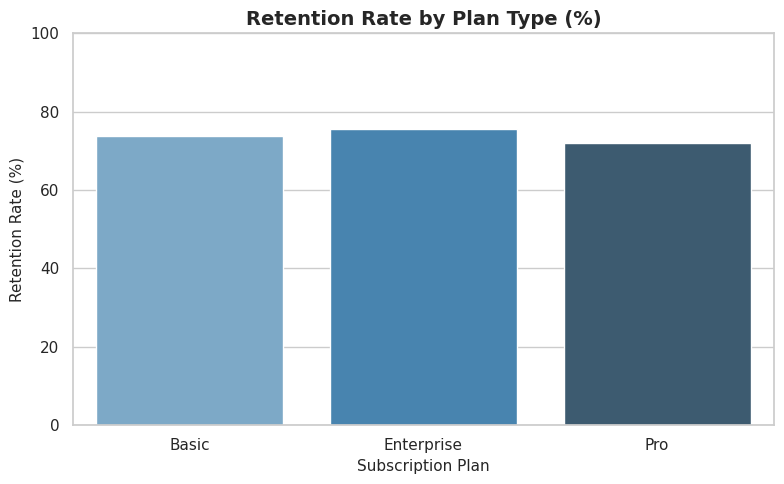

In [ ]:
# Calculate retention rate per plan
plan_ret = df_subs.groupby('plan_type', as_index=False).agg(
    total_users=('user_id', 'count'),
    active_users=('churn_status', lambda x: (x == 'Active').sum())
)
plan_ret['retention_rate'] = (plan_ret['active_users'] / plan_ret['total_users']) * 100

# Create and display plot

plt.figure(figsize=(8, 5))
sns.barplot(
    data=plan_ret,
    x='plan_type',
    y='retention_rate',
    hue='plan_type',
    palette='Blues_d',
    legend=False
)
plt.title("Retention Rate by Plan Type (%)", fontsize=14, fontweight='bold')
plt.xlabel("Subscription Plan", fontsize=11)
plt.ylabel("Retention Rate (%)", fontsize=11)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

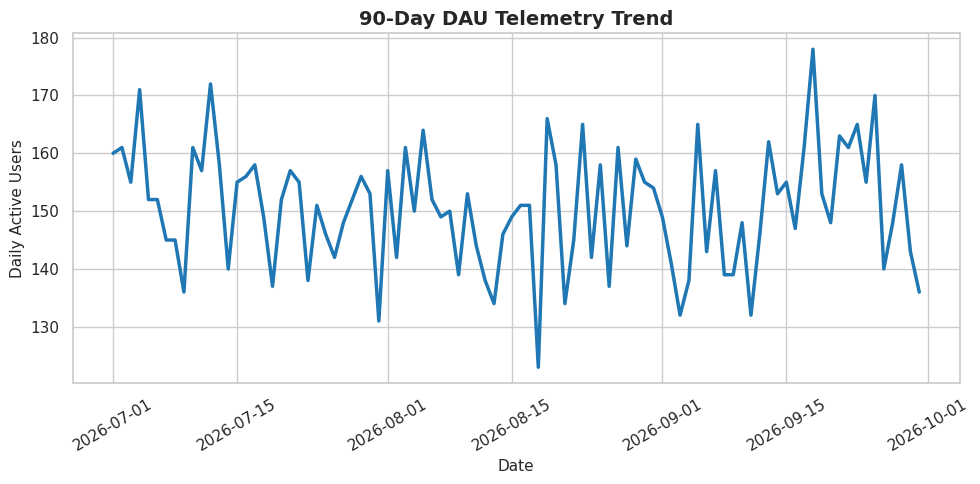

In [ ]:
# Calculate daily active users
dau_trend = df_act.groupby('session_date')['user_id'].nunique().reset_index()

# Create and display plot
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=dau_trend,
    x='session_date',
    y='user_id',
    color='#1f77b4',
    linewidth=2.5
)
plt.title("90-Day DAU Telemetry Trend", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=11)
plt.ylabel("Daily Active Users", fontsize=11)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

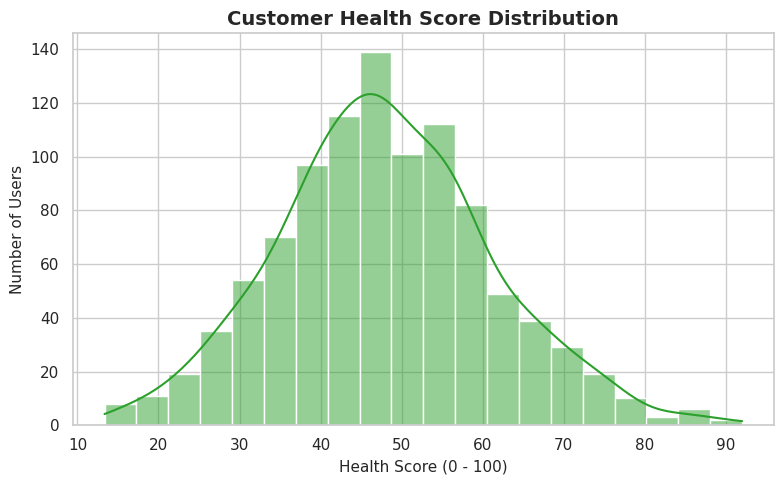

In [ ]:
# Create and display plot
plt.figure(figsize=(8, 5))
sns.histplot(
    user_agg['health_score'],
    kde=True,
    color='#2ca02c',
    bins=20
)
plt.title("Customer Health Score Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Health Score (0 - 100)", fontsize=11)
plt.ylabel("Number of Users", fontsize=11)
plt.tight_layout()
plt.show()